# CS3244 Group 20 — SARC Sarcasm Detection

---
## 0. Setup & Imports

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import emoji
from transformers import AutoTokenizer
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

SEED = 42
print('Imports OK')

Imports OK


---
## 1. Load Data

In [24]:
train_df = pd.read_csv('data/train-balanced.csv.bz2',
                       compression='bz2', sep='\t', header=None,
                       names=['label', 'comment', 'author', 'subreddit',
                              'score', 'ups', 'downs', 'date', 'created_utc', 'parent_comment'])

test_df = pd.read_csv('data/test-balanced.csv.bz2',
                      compression='bz2', sep='\t', header=None,
                      names=['label', 'comment', 'author', 'subreddit',
                             'score', 'ups', 'downs', 'date', 'created_utc', 'parent_comment'])

print('Train shape:', train_df.shape)
print('Test shape: ', test_df.shape)
train_df.head()

Train shape: (1125678, 10)
Test shape:  (283334, 10)


,label,comment,author,subreddit,score,ups,downs,date,created_utc,parent_comment
0,0,"Dang dog, thanks",Mattys1174,NHLHUT,1,-1,-1,2017-03,1490927299,Great guess! Congrats!
1,0,to summon the powers of the flying spaghetti m...,yugiohhero,CringeAnarchy,1,-1,-1,2017-02,1486349313,can anynone explain what cash me outside means?
2,0,i did that 3rd last 1 by accident last night,yugiohhero,TownofSalemgame,8,-1,-1,2017-03,1488514232,I have seen all these things
3,0,"He's insane, used him in DC, better than Blake...",masternater6,NHLHUT,1,-1,-1,2017-02,1486097950,ASG Weber review request Looking to pick him u...
4,0,"Forgot about him, he's a pretty pointless card...",masternater6,NHLHUT,1,-1,-1,2017-04,1491597507,Modano at least plays to his overall.


In [25]:
print('Columns:', list(train_df.columns))
print('\nDtypes:')
print(train_df.dtypes)

Columns: ['label', 'comment', 'author', 'subreddit', 'score', 'ups', 'downs', 'date', 'created_utc', 'parent_comment']

Dtypes:
label             int64
comment             str
author              str
subreddit           str
score             int64
ups               int64
downs             int64
date                str
created_utc       int64
parent_comment      str
dtype: object


Data Analysis

In [26]:
print('=== Label distribution (train) ===')
print(train_df['label'].value_counts())
print(f"\nSarcasm rate: {train_df['label'].mean():.2%}")

print('\n=== Label distribution (test) ===')
print(test_df['label'].value_counts())
print(f"\nSarcasm rate: {test_df['label'].mean():.2%}")

=== Label distribution (train) ===
label
0    562839
1    562839
Name: count, dtype: int64

Sarcasm rate: 50.00%

=== Label distribution (test) ===
label
0    141667
1    141667
Name: count, dtype: int64

Sarcasm rate: 50.00%


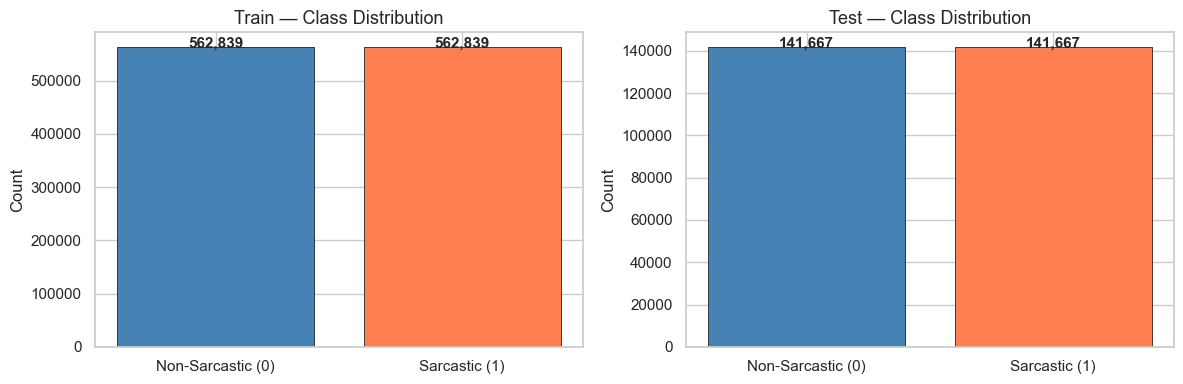

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, df) in zip(axes, [('Train', train_df), ('Test', test_df)]):
    counts = df['label'].value_counts().sort_index()
    bars = ax.bar(['Non-Sarcastic (0)', 'Sarcastic (1)'],
                  counts.values, color=['steelblue', 'coral'], edgecolor='black', linewidth=0.5)
    ax.set_title(f'{name} — Class Distribution', fontsize=13)
    ax.set_ylabel('Count')
    for bar, v in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, v + 50, f'{v:,}',
                ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()

plt.show()

**Observation:** The class are perfectly balanced in the trained and test set with 50% of Non-sarcastic and 50% of sarcastic

### 2.2 Comment Length Distribution

In [28]:
train_df['comment_len'] = train_df['comment'].astype(str).str.len()
train_df['word_count']  = train_df['comment'].astype(str).str.split().str.len()

print('=== Comment length stats by label ===')
print(train_df.groupby('label')[['comment_len', 'word_count']].describe().round(1))

=== Comment length stats by label ===
      comment_len                                             word_count  \
            count  mean   std  min   25%   50%   75%      max      count   
label                                                                      
0        562831.0  56.9  77.8  1.0  24.0  44.0  75.0  10000.0   562831.0   
1        562836.0  56.8  40.7  1.0  30.0  48.0  73.0   9921.0   562836.0   

                                                
       mean   std  min  25%  50%   75%     max  
label                                           
0      10.6  12.4  1.0  4.0  8.0  14.0  2222.0  
1      10.4   7.0  1.0  6.0  9.0  14.0   257.0  


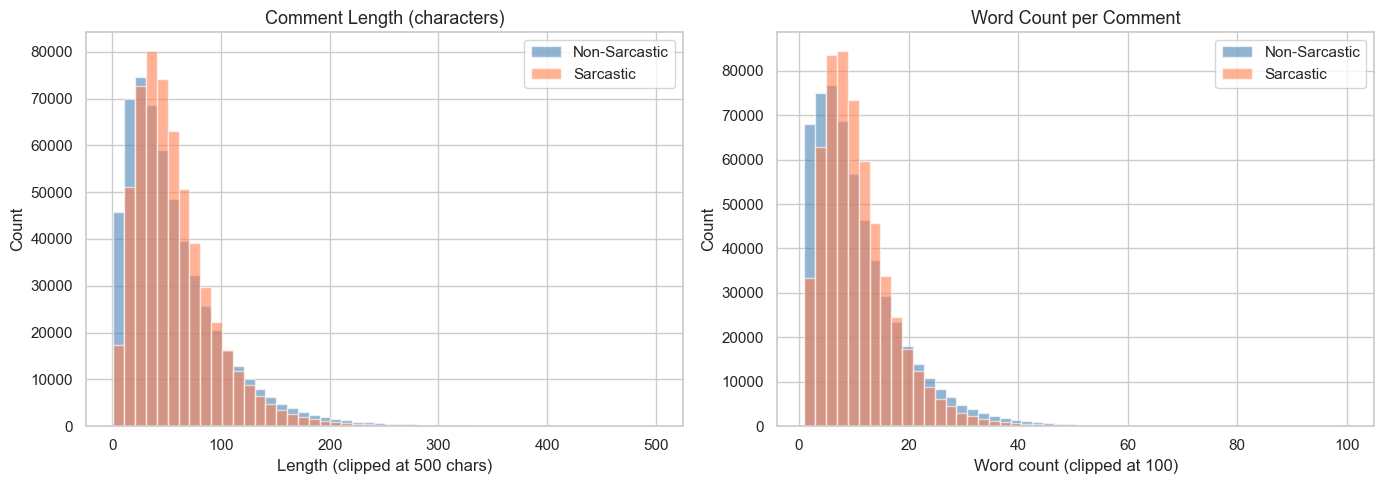

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels_info = [(0, 'steelblue', 'Non-Sarcastic'), (1, 'coral', 'Sarcastic')]

# Character length
for label, color, name in labels_info:
    data = train_df[train_df['label'] == label]['comment_len'].clip(upper=500)
    axes[0].hist(data, bins=50, alpha=0.6, color=color, label=name)
axes[0].set_title('Comment Length (characters)', fontsize=13)
axes[0].set_xlabel('Length (clipped at 500 chars)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Word count
for label, color, name in labels_info:
    data = train_df[train_df['label'] == label]['word_count'].clip(upper=100)
    axes[1].hist(data, bins=50, alpha=0.6, color=color, label=name)
axes[1].set_title('Word Count per Comment', fontsize=13)
axes[1].set_xlabel('Word count (clipped at 100)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.show()

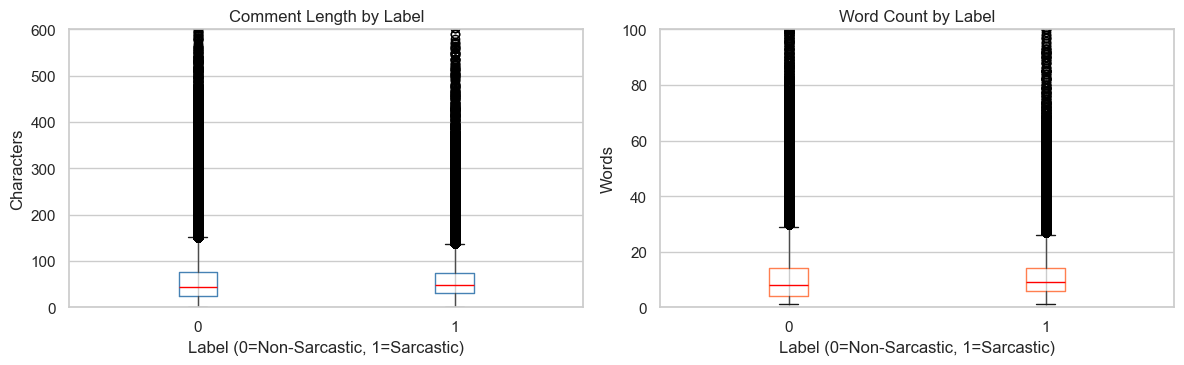

In [30]:
# Boxplot comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df.boxplot(column='comment_len', by='label', ax=axes[0],
                 boxprops=dict(color='steelblue'), medianprops=dict(color='red'))
axes[0].set_title('Comment Length by Label')
axes[0].set_xlabel('Label (0=Non-Sarcastic, 1=Sarcastic)')
axes[0].set_ylabel('Characters')
axes[0].set_ylim(0, 600)

train_df.boxplot(column='word_count', by='label', ax=axes[1],
                 boxprops=dict(color='coral'), medianprops=dict(color='red'))
axes[1].set_title('Word Count by Label')
axes[1].set_xlabel('Label (0=Non-Sarcastic, 1=Sarcastic)')
axes[1].set_ylabel('Words')
axes[1].set_ylim(0, 100)

plt.suptitle('')
plt.tight_layout()
plt.show()

**Observation:** Sarcastic and non-sarcastic comments have very similar length distributions, with medians of 48 vs 44 characters and ~9 vs 8 words respectively. Both classes are right-skewed, with most comments being short (under 100 characters). The main difference is that non-sarcastic comments are more variable in length (std 77.8 vs 40.7), suggesting sarcastic remarks tend to be more concise and punchy. Overall, comment length is a weak standalone feature for sarcasm detection, but may serve as a useful auxiliary signal alongside text-based models.

### 2.3 Subreddit Distribution

/var/folders/68/0kljsdk55fl7rzbd59kfvhcw0000gn/T/ipykernel_54291/1107967013.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_subreddits.values, y=top_subreddits.index, palette='viridis')


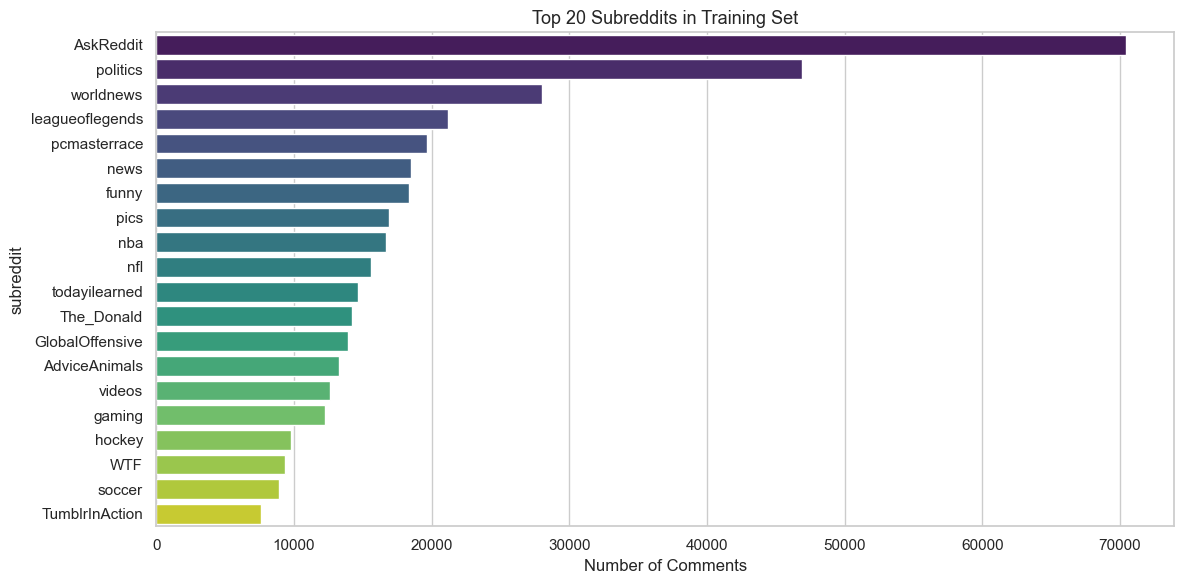


Total unique subreddits: 16326


In [31]:
top_subreddits = train_df['subreddit'].value_counts().head(20)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_subreddits.values, y=top_subreddits.index, palette='viridis')
plt.title('Top 20 Subreddits in Training Set', fontsize=13)
plt.xlabel('Number of Comments')
plt.tight_layout()
plt.show()


print(f'\nTotal unique subreddits: {train_df["subreddit"].nunique()}')

                 sarcasm_rate  total
subreddit                           
worldnews               0.645  27999
TumblrInAction          0.619   7644
politics                0.607  46914
news                    0.600  18529
pcmasterrace            0.568  19675
GlobalOffensive         0.561  13959
AdviceAnimals           0.561  13287
todayilearned           0.549  14619
soccer                  0.547   8899
leagueoflegends         0.543  21173
hockey                  0.526   9776
nba                     0.516  16696
nfl                     0.505  15585
pics                    0.494  16876
videos                  0.494  12597
gaming                  0.493  12278
The_Donald              0.484  14239
funny                   0.451  18344
WTF                     0.448   9359
AskReddit               0.399  70409


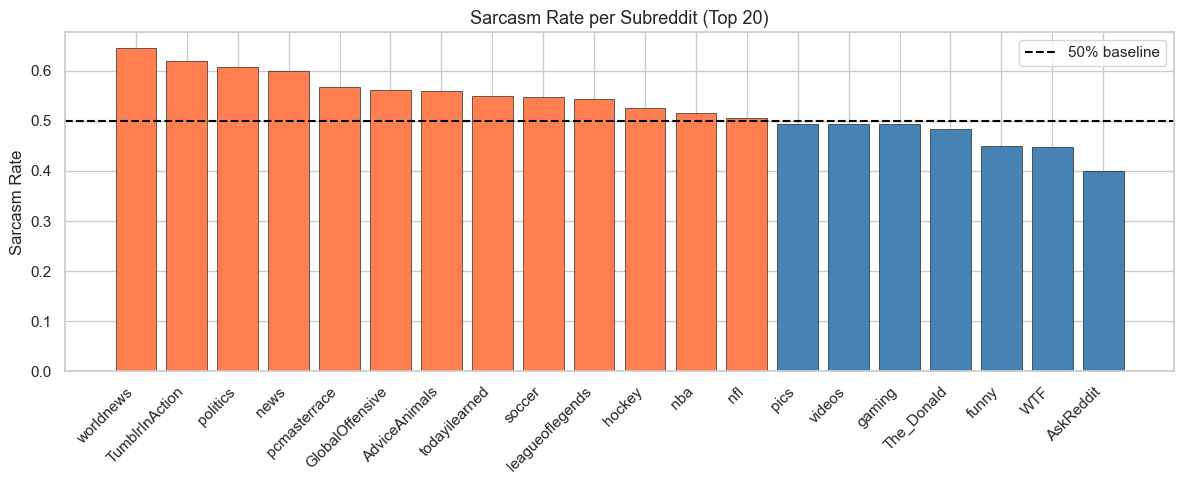

In [32]:
# Sarcasm rate per subreddit (top 20 most represented)
top_subs = train_df['subreddit'].value_counts().head(20).index
sarc_rate = (train_df[train_df['subreddit'].isin(top_subs)]
             .groupby('subreddit')['label']
             .agg(['mean', 'count'])
             .rename(columns={'mean': 'sarcasm_rate', 'count': 'total'})
             .sort_values('sarcasm_rate', ascending=False))

print(sarc_rate.round(3))

plt.figure(figsize=(12, 5))
colors = ['coral' if r > 0.5 else 'steelblue' for r in sarc_rate['sarcasm_rate']]
plt.bar(sarc_rate.index, sarc_rate['sarcasm_rate'], color=colors, edgecolor='black', linewidth=0.4)
plt.axhline(0.5, color='black', linestyle='--', linewidth=1.5, label='50% baseline')
plt.title('Sarcasm Rate per Subreddit (Top 20)', fontsize=13)
plt.ylabel('Sarcasm Rate')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

**Observation:** The sarcasm rate varies significantly across subreddits, suggesting that community culture plays an important role in sarcastic expression. News and politics-oriented subreddits such as worldnews (64.5%), politics (60.7%) and news (60.0%) show the highest sarcasm rates, likely because users tend to express frustration or disagreement indirectly through sarcasm rather than direct criticism. TumblrInAction (61.9%) is also notably high, as the subreddit is culturally centred around mocking content, making sarcasm the dominant tone. On the other end, AskReddit (39.9%) has the lowest rate among the top subreddits, consistent with its question-and-answer format where users are expected to respond sincerely. Interestingly, funny and WTF also show below-average sarcasm rates (45%), suggesting that reaction-based communities rely less on sarcasm than debate-driven ones.

### 2.4 Score Distribution

In [33]:
print('=== Score stats by label ===')
print(train_df.groupby('label')['score'].describe().round(2))

=== Score stats by label ===
          count  mean    std    min  25%  50%  75%     max
label                                                     
0      562839.0  7.54  56.33 -645.0  1.0  2.0  4.0  8959.0
1      562839.0  6.26  30.73 -312.0  1.0  2.0  5.0  3689.0


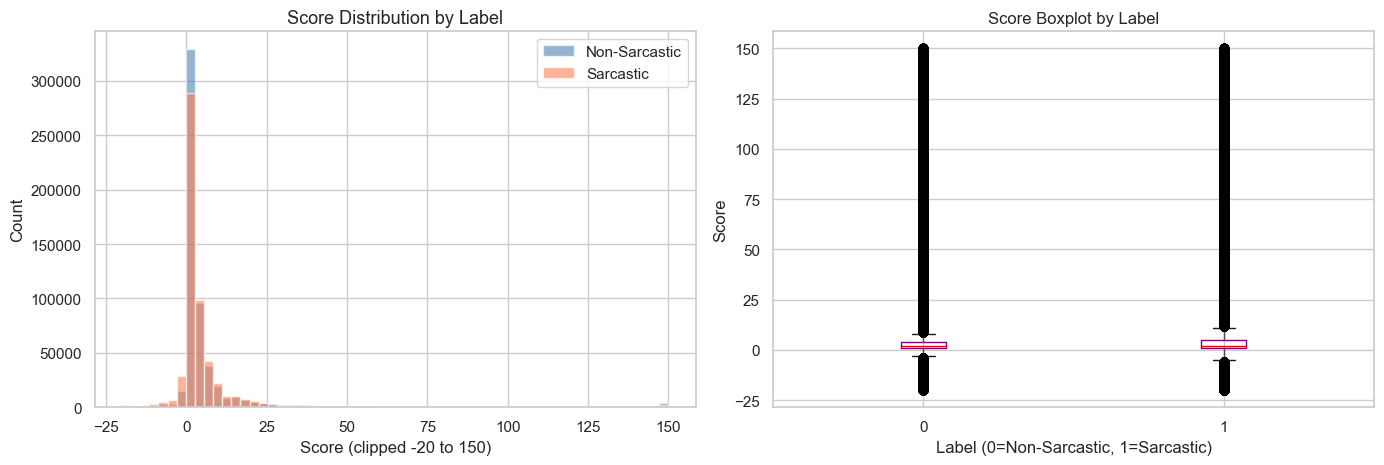

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
for label, color, name in labels_info:
    data = train_df[train_df['label'] == label]['score'].clip(-20, 150)
    axes[0].hist(data, bins=60, alpha=0.6, color=color, label=name)
axes[0].set_title('Score Distribution by Label', fontsize=13)
axes[0].set_xlabel('Score (clipped -20 to 150)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Boxplot
train_df[train_df['score'].between(-20, 150)].boxplot(
    column='score', by='label', ax=axes[1],
    boxprops=dict(color='purple'), medianprops=dict(color='red')
)
axes[1].set_title('Score Boxplot by Label')
axes[1].set_xlabel('Label (0=Non-Sarcastic, 1=Sarcastic)')
axes[1].set_ylabel('Score')
plt.suptitle('')

plt.tight_layout()
plt.show()

**Observation:** Both classes show a heavily right-skewed distribution, with the vast majority of comments clustered around a score of 0–5 regardless of label. The median score is identical for both classes (2), and the boxplots confirm that the interquartile ranges are nearly indistinguishable. The main difference lies in the variance — non-sarcastic comments have a much higher standard deviation (56.3 vs 30.7), meaning they occasionally reach very high scores (max 8959 vs 3689), while sarcastic comments tend to stay more moderate. Overall, score is a very weak feature for sarcasm detection — the distributions overlap almost entirely, suggesting that community upvoting behaviour does not reliably reflect sarcastic intent.

---
## 2.5 Summary of my observation


| Observation | Résultat |
|---|---|
| Class balance (train) | 50/50 |
| Longueur moyenne — sarcastic | 56.8 chars / 10.4 mots |
| Longueur moyenne — non-sarcastic | 56.9 chars / 10.6 mots |
| Subreddit le plus représenté | AskReddit |
| Subreddit avec le plus haut taux de sarcasme | worldnews |
| Score moyen — sarcastic vs non-sarcastic | 6.26 vs 7.54 |
| Lignes supprimées (train) | 11 |

**Conclusion EDA :**  

The dataset is well-balanced and large-scale (1.1M training comments). Comment length and score are weak standalone features, as both classes show very similar distributions. The most informative signal from the EDA is the subreddit of origin, which shows notable variation in sarcasm rate across communities.


---
## 3. Preprocessing

In [35]:
def basic_clean(text):
    if pd.isna(text) or str(text).strip() == '':
        return None
    return str(text).strip()

train_df['comment_clean'] = train_df['comment'].apply(basic_clean)
test_df['comment_clean']  = test_df['comment'].apply(basic_clean)


before_train = len(train_df)
before_test  = len(test_df)

train_df.dropna(subset=['comment_clean'], inplace=True)
test_df.dropna(subset=['comment_clean'],  inplace=True)

print(f'Train: deleted {before_train - len(train_df)} empty lines → {len(train_df)} remaining')
print(f'Test:  deleted {before_test  - len(test_df)}  empty lines → {len(test_df)} remaining')

Train: deleted 11 empty lines → 1125667 remaining
Test:  deleted 2  empty lines → 283332 remaining


### 3.2 Normalization of the text

In [ ]:
def normalize_text(text):
    """
    - Lowercase
    - delete URLs
    - delete @mentions and #hashtags
    - delete whitespace en trop
    we keep punctuation for BERT
    """
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)   # URLs
    text = re.sub(r'@\w+', '', text)              # @mentions
    text = re.sub(r'#\w+', '', text)              # hashtags
    text = re.sub(r'\s+', ' ', text).strip()      # whitespace
    return text

train_df['text_normalized'] = train_df['comment_clean'].apply(normalize_text)
test_df['text_normalized']  = test_df['comment_clean'].apply(normalize_text)



We realised that the dataset does not contain emojis, but we kept the demojize_text just in case

In [37]:
def demojize_text(text):
    return emoji.demojize(text)
train_df["comment_clean"] = train_df["comment_clean"].apply(demojize_text)
test_df["comment_clean"]  = test_df["comment_clean"].apply(demojize_text)

### 3.2.1 Parent comment (added context)

For sarcasm detection, the parent comment is important context (reply-to). We normalize it the same way as the main comment so we can feed (parent, comment) pairs to BERT. Missing parents become empty string.

In [40]:
# Parent comment: same pipeline as comment (clean, demojize, normalize). NaN -> empty string.
def safe_clean(s):
    if pd.isna(s) or str(s).strip() == '':
        return ''
    return (basic_clean(s) or '')

train_df['parent_comment_clean'] = train_df['parent_comment'].fillna('').apply(safe_clean)
train_df['parent_comment_clean'] = train_df['parent_comment_clean'].apply(demojize_text)
train_df['parent_text_normalized'] = train_df['parent_comment_clean'].apply(normalize_text)

test_df['parent_comment_clean'] = test_df['parent_comment'].fillna('').apply(safe_clean)
test_df['parent_comment_clean'] = test_df['parent_comment_clean'].apply(demojize_text)
test_df['parent_text_normalized'] = test_df['parent_comment_clean'].apply(normalize_text)

print('Parent context columns added. Sample (first row):')
print(train_df[['parent_comment', 'parent_text_normalized']].iloc[0].to_string())

Parent context columns added. Sample (first row):
parent_comment            Great guess! Congrats!
parent_text_normalized    great guess! congrats!


In [41]:

def remove_punctuation(text):
    text = re.sub(r'[^\w\s]', '', str(text))
    return re.sub(r'\s+', ' ', text).strip()

train_df['text_no_punct'] = train_df['text_normalized'].apply(remove_punctuation)
test_df['text_no_punct']  = test_df['text_normalized'].apply(remove_punctuation)


### 3.3 Export of cleaned data


In [ ]:
KEEP_COLS = [
    'label',
    'comment',            
    'comment_clean',      
    'text_normalized',     
    'parent_comment',      
    'parent_text_normalized',
    'text_no_punct',       
    'subreddit',
    'score',
    'comment_len',
    'word_count',
]

train_out = train_df[[c for c in KEEP_COLS if c in train_df.columns]]
test_out  = test_df[[c  for c in KEEP_COLS if c in test_df.columns]]

train_out.to_csv('data/train_cleaned.csv', index=False)
test_out.to_csv('data/test_cleaned.csv',   index=False)

print(f'Saved : data/train_cleaned.csv  ({len(train_out):,} lignes)')
print(f'Saved : data/test_cleaned.csv   ({len(test_out):,} lignes)')


Sauvegardé : train_cleaned.csv  (1,125,667 lignes)
Sauvegardé : test_cleaned.csv   (283,332 lignes)


---
## 4. Tokenisation

This section prepares text for a BERT-style model. It requires `transformers` and `torch` (add them to `requirements.txt` and install if needed). We load a BERT tokenizer and define: (1) `SarcasmDataset` for comment-only input; (2) `SarcasmDatasetWithContext` for (parent, comment) pairs with segment IDs and truncation so the comment is kept intact.

In [45]:
# Tokenisation: load BERT tokenizer and set encode params

TOKENIZER_NAME = 'bert-base-uncased'
MAX_LENGTH = 128
MAX_LENGTH_PAIR = 256   # for (parent, comment) pairs; parent truncated first so comment is kept
TEXT_COL = 'text_normalized'  # use normalized text (demojized text is in comment_clean)
PARENT_COL = 'parent_text_normalized'

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

def tokenize_texts(texts, tokenizer=tokenizer, max_length=MAX_LENGTH):
    """Encode a list of texts to input_ids and attention_mask."""
    enc = tokenizer(
        list(texts),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt',
        return_token_type_ids=False,
    )
    return enc['input_ids'], enc['attention_mask']

print(f'Tokenizer: {TOKENIZER_NAME}, max_length={MAX_LENGTH}')
print(f'Vocabulary size: {tokenizer.vocab_size}')

Tokenizer: bert-base-uncased, max_length=128
Vocabulary size: 30522


In [46]:
# PyTorch Dataset: tokenises on the fly

class SarcasmDataset(Dataset):
    """Dataset that yields tokenised (input_ids, attention_mask) and label for each row."""
    def __init__(self, df, tokenizer, text_col=TEXT_COL, label_col='label', max_length=MAX_LENGTH):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.text_col = text_col
        self.label_col = label_col
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        text = row[self.text_col]
        if pd.isna(text):
            text = ''
        text = str(text).strip()
        encoded = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors='pt',
            return_token_type_ids=False,
        )
        return {
            'input_ids': encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'label': torch.tensor(row[self.label_col], dtype=torch.long),
        }

# Example: build datasets from current train_df / test_df (run after preprocessing)
# train_ds = SarcasmDataset(train_df, tokenizer)
# test_ds  = SarcasmDataset(test_df, tokenizer)
# Then use with DataLoader: DataLoader(train_ds, batch_size=32, shuffle=True)
train_ds = SarcasmDataset(train_df, tokenizer)
test_ds = SarcasmDataset(test_df, tokenizer)
print(f'Train dataset size: {len(train_ds)}, Test dataset size: {len(test_ds)}')

Train dataset size: 1125667, Test dataset size: 283332


In [47]:
# Dataset with parent as context: [CLS] parent [SEP] comment [SEP] with token_type_ids (0=parent, 1=comment).
# Truncation 'only_first' keeps the comment intact and truncates the parent when over max_length.

class SarcasmDatasetWithContext(Dataset):
    """Dataset that tokenises (parent, comment) pairs with segment IDs for BERT."""
    def __init__(self, df, tokenizer, parent_col=PARENT_COL, text_col=TEXT_COL, label_col='label', max_length=MAX_LENGTH_PAIR):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.parent_col = parent_col
        self.text_col = text_col
        self.label_col = label_col
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        parent = row[self.parent_col]
        text = row[self.text_col]
        if pd.isna(parent):
            parent = ''
        if pd.isna(text):
            text = ''
        parent, text = str(parent).strip(), str(text).strip()
        encoded = self.tokenizer(
            parent,
            text,
            padding='max_length',
            truncation='only_first',
            max_length=self.max_length,
            return_tensors='pt',
            return_token_type_ids=True,
        )
        return {
            'input_ids': encoded['input_ids'].squeeze(0),
            'attention_mask': encoded['attention_mask'].squeeze(0),
            'token_type_ids': encoded['token_type_ids'].squeeze(0),
            'label': torch.tensor(row[self.label_col], dtype=torch.long),
        }

train_ds_ctx = SarcasmDatasetWithContext(train_df, tokenizer)
test_ds_ctx = SarcasmDatasetWithContext(test_df, tokenizer)
print(f'With context — Train: {len(train_ds_ctx)}, Test: {len(test_ds_ctx)} (max_length={MAX_LENGTH_PAIR}, truncation=only_first)')

With context — Train: 1125667, Test: 283332 (max_length=256, truncation=only_first)


In [48]:
# Sanity check: tokenise a few examples and decode back
examples = train_df[TEXT_COL].dropna().head(3).tolist()
for i, text in enumerate(examples):
    enc = tokenizer(text, padding='max_length', truncation=True, max_length=MAX_LENGTH, return_tensors='pt')
    decoded = tokenizer.decode(enc['input_ids'][0], skip_special_tokens=False)
    print(f'--- Example {i+1} ---')
    print(f'Original (first 80 chars): {str(text)[:80]}...' if len(str(text)) > 80 else f'Original: {text}')
    print(f'Decoded (first 80 chars): {decoded[:80]}...' if len(decoded) > 80 else f'Decoded: {decoded}')
    print()

--- Example 1 ---
Original: dang dog, thanks
Decoded (first 80 chars): [CLS] dang dog, thanks [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PA...

--- Example 2 ---
Original (first 80 chars): to summon the powers of the flying spaghetti monster to turn him into money whil...
Decoded (first 80 chars): [CLS] to summon the powers of the flying spaghetti monster to turn him into mone...

--- Example 3 ---
Original: i did that 3rd last 1 by accident last night
Decoded (first 80 chars): [CLS] i did that 3rd last 1 by accident last night [SEP] [PAD] [PAD] [PAD] [PAD]...



---
## 5. Data loaders for model training

Handoff for the model implementation. Below we:
- Split the training set into **train** and **validation** (stratified, fixed seed).
- Build PyTorch `DataLoader`s with a sensible batch size.

To get started on the next part can use `train_loader` and `val_loader` (and optionally `test_loader`) directly in a training loop. Each batch is a dict with `input_ids`, `attention_mask`, `label`; use `train_ds_ctx` / `train_loader_ctx` if the model uses parent context (adds `token_type_ids`).

In [50]:
# Stratified train/val split (e.g. 90% train, 10% val)
VAL_RATIO = 0.10
BATCH_SIZE = 32
NUM_WORKERS = 0  # set > 0 if you want multi-process loading

train_idx, val_idx = train_test_split(
    np.arange(len(train_df)),
    test_size=VAL_RATIO,
    stratify=train_df['label'],
    random_state=SEED,
)

train_subset = train_df.iloc[train_idx].reset_index(drop=True)
val_subset   = train_df.iloc[val_idx].reset_index(drop=True)

# Datasets (comment-only)
train_ds_split = SarcasmDataset(train_subset, tokenizer)
val_ds         = SarcasmDataset(val_subset, tokenizer)

# Datasets with parent context (optional)
train_ds_ctx_split = SarcasmDatasetWithContext(train_subset, tokenizer)
val_ds_ctx         = SarcasmDatasetWithContext(val_subset, tokenizer)

# DataLoaders — comment-only
train_loader = DataLoader(train_ds_split, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader   = DataLoader(val_ds,         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# DataLoaders — with context (for BERT that uses parent + comment)
train_loader_ctx = DataLoader(train_ds_ctx_split, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader_ctx   = DataLoader(val_ds_ctx,         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader_ctx  = DataLoader(test_ds_ctx,        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f'Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}')
print(f'Train samples: {len(train_subset):,}, Val samples: {len(val_subset):,}')

Train batches: 31660, Val batches: 3518, Test batches: 8855
Train samples: 1,013,100, Val samples: 112,567
